# Week 9 — Part a — Neural Networks


This notebook follows the neural-network section of the lecture. We will start with the artificial neuron, connect it to logistic regression, and then train a small **multilayer perceptron (MLP)** on a non-linear classification problem.

### Learning objectives

By the end, you should be able to:

- calculate the output of a simple artificial neuron;
- explain why activation functions introduce non-linearity;
- identify input, hidden and output layers in an MLP;
- train and evaluate a neural network for classification;

The synthetic dataset for this notebook is in `../data/week9_two_moons.csv`.



## 1. From logistic regression to an artificial neuron

An artificial neuron performs two operations:

1. It calculates a **weighted sum** of its inputs, including a bias:

   $$
   z = w_1x_1 + w_2x_2 + \cdots + b
   $$

2. It applies an **activation function** to that sum:

   $$
   \hat{y} = \sigma(z)
   $$

For the sigmoid activation,

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The output is between 0 and 1. Yes! You have guessed correctly! With a sigmoid activation, a single artificial neuron is mathematically equivalent to logistic regression.

The next example uses the numbers from the lecture's neuron diagram which is also fake data.
The idea is to predict the health status of participants from their sleep and exercise.

In [1]:
import numpy as np

# Inputs
x1 = 6  # sleep (hours)
x2 = 1  # exercise 

# Parameters (weights and bias)
w1 = -0.5
w2 = -0.8
b = 4

# Step 1: weighted sum
z = w1 * x1 + w2 * x2 + b

# Step 2: sigmoid activation
sigmoid = lambda value: 1 / (1 + np.exp(-value))
prediction = sigmoid(z)

print(f"Weighted sum z: {z:.2f}")
print(f"Neuron output:  {prediction:.2f}")

Weighted sum z: 0.20
Neuron output:  0.55


**Think about it**

1. What happens to the weighted sum if `w1` becomes more negative?
2. What is the role of the bias `b`?
3. Why is the sigmoid output useful when predicting the probability of a class? (review your Logistic Regression lecture reasons again)


## 2. Activation functions

An activation function transforms the weighted sum before it is passed to the next layer.

Three common examples from the lecture are:

- **Sigmoid:** maps values to the interval $(0, 1)$; often useful at the output of a binary classifier. In Logistic Regression, we liked it because it was mapping to the range that is also feasible as probability.
- **Tanh:** maps values to $(-1, 1)$.
- **ReLU:** returns $\max(0, z)$; a common choice in hidden layers.

Without a non-linear activation, stacking layers does not create a more expressive model: a linear function applied to another linear function is still linear.

This is how these three functions look:

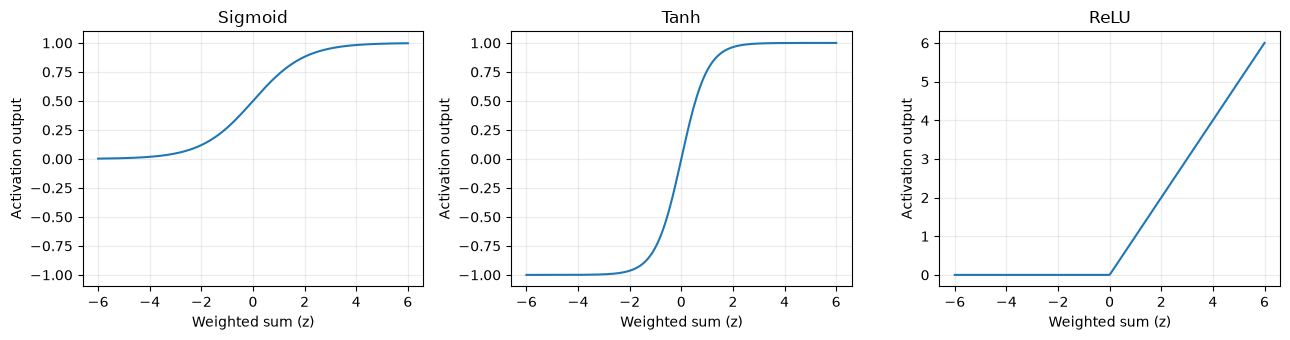

In [2]:
import matplotlib.pyplot as plt

z_values = np.linspace(-6, 6, 300)
sigmoid_values = 1 / (1 + np.exp(-z_values))
tanh_values = np.tanh(z_values)
relu_values = np.maximum(0, z_values)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(z_values, sigmoid_values)
axes[0].set_title("Sigmoid")
axes[0].set_ylim(-1.1, 1.1)

axes[1].plot(z_values, tanh_values)
axes[1].set_title("Tanh")
axes[1].set_ylim(-1.1, 1.1)

axes[2].plot(z_values, relu_values)
axes[2].set_title("ReLU")

for ax in axes:
    ax.set_xlabel("Weighted sum (z)")
    ax.set_ylabel("Activation output")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 3. A non-linear classification problem

A single sigmoid neuron can only produce a monotonic S-shaped relationship for one input. Combining neurons in hidden layers allows a network to model more complex, non-linear patterns.

We will use a small synthetic dataset called **two moons**. It is a famous example of two classes that you can't separate with a straight line. The two classes form interleaving crescent shapes, a straight decision boundary is not sufficient to separate them well.

The target (`y`) is provided, so this is a **supervised classification** task.

In [3]:
import pandas as pd

moons = pd.read_csv("../data/week9_two_moons.csv")
feature_names = ["feature_1", "feature_2"]

X = moons[feature_names].to_numpy()
y = moons["target"].to_numpy()

moons.head()

,feature_1,feature_2,target
0,0.6521,1.0540,0
1,0.7006,-0.4322,1
2,1.5338,0.0429,1
3,0.9383,0.6582,0
4,-0.3125,0.6164,0


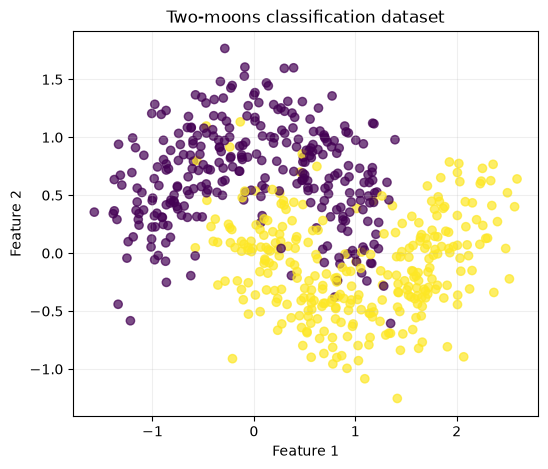

In [4]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-moons classification dataset")
plt.grid(alpha=0.2)
plt.show()

## 4. Split the data and establish a baseline

We will compare the neural network with logistic regression. Reminder: The standardisation step is placed inside a scikit-learn `Pipeline`, so the scaler is fitted using the training data only.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print(f"Logistic regression test accuracy: {accuracy_score(y_test, logistic_predictions):.3f}")
print("\nClassification report:")
print(classification_report(y_test, logistic_predictions))

Logistic regression test accuracy: 0.847

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84        75
           1       0.83      0.87      0.85        75

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150



A useful way to compare classifiers is to visualise their **decision boundary**. The shaded regions show which class the model predicts at different positions in the feature space.

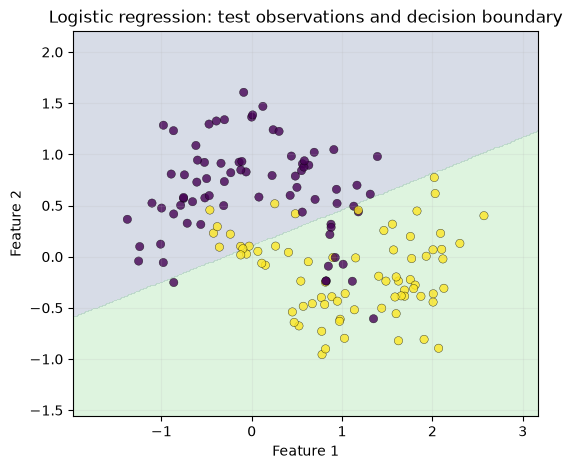

In [6]:
def plot_decision_boundary(model, X_data, y_data, title):
    """Plot a two-dimensional classifier's decision regions and observations."""
    x_min, x_max = X_data[:, 0].min() - 0.6, X_data[:, 0].max() + 0.6
    y_min, y_max = X_data[:, 1].min() - 0.6, X_data[:, 1].max() + 0.6
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    predicted_classes = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, predicted_classes, alpha=0.2, levels=[-0.5, 0.5, 1.5])
    plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data, edgecolor="black", linewidth=0.3, alpha=0.8)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.grid(alpha=0.15)
    plt.show()


plot_decision_boundary(
    logistic_model,
    X_test,
    y_test,
    "Logistic regression: test observations and decision boundary"
)

**Observe:** Does the logistic-regression boundary follow the curved shape of the two classes? What does this suggest about the limits of a model with a linear decision boundary?

## 5. Train a multilayer perceptron (MLP)

A **multilayer perceptron** connects neurons in layers:

- **Input layer:** receives the features; it does not perform a learned transformation itself.
- **Hidden layer(s):** learn intermediate representations of the inputs.
- **Output layer:** produces the prediction.

In a fully connected, feedforward MLP, every neuron connects to all neurons in the next layer, and information flows from input to output without loops.

We will use `MLPClassifier` from scikit-learn. The network has one hidden layer with 12 neurons and ReLU activation. The estimator handles the forward pass, loss calculation, backpropagation and weight updates during `.fit()`.
One full pass through the training data is called an **epoch**. Training repeats for many epochs; `max_iter=2000` sets the maximum number, and scikit-learn stops earlier once the loss stops improving if you tell it "early_stopping=True" [we do it at the end].

In [7]:
from sklearn.neural_network import MLPClassifier

neural_network = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(12,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.01,
        max_iter=2000,
        random_state=42
    ))
])

neural_network.fit(X_train, y_train)
mlp_predictions = neural_network.predict(X_test)

print(f"MLP test accuracy: {accuracy_score(y_test, mlp_predictions):.3f}")
print("\nClassification report:")
print(classification_report(y_test, mlp_predictions))

MLP test accuracy: 0.907

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        75
           1       0.91      0.91      0.91        75

    accuracy                           0.91       150
   macro avg       0.91      0.91      0.91       150
weighted avg       0.91      0.91      0.91       150



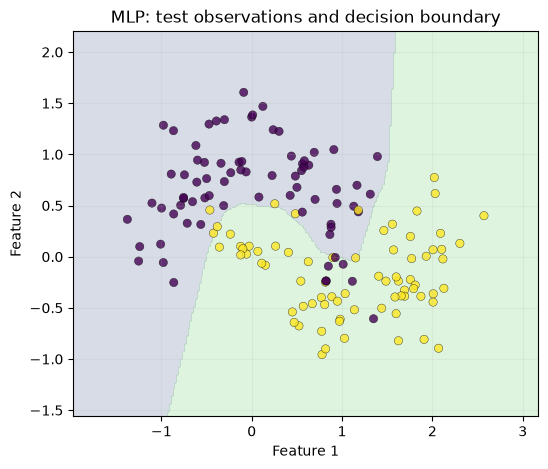

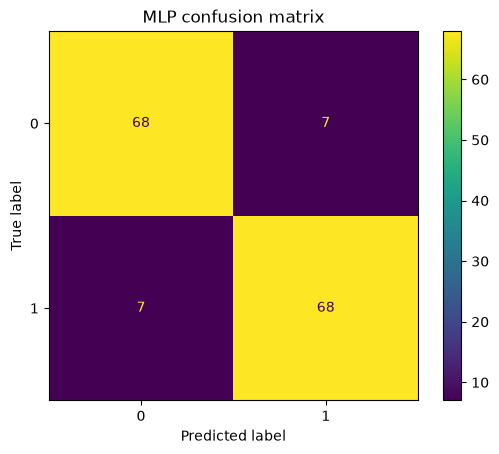

In [8]:
plot_decision_boundary(
    neural_network,
    X_test,
    y_test,
    "MLP: test observations and decision boundary"
)

ConfusionMatrixDisplay.from_predictions(y_test, mlp_predictions)
plt.title("MLP confusion matrix")
plt.show()

### Compare the two models

Accuracy is one summary measure, but as we discussed in the class, it does not describe every type of error. Use the confusion matrix and classification report to inspect performance more carefully.

In [9]:
comparison = pd.DataFrame({
    "model": ["Logistic regression", "MLP"],
    "test_accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, mlp_predictions)
    ]
})

comparison

,model,test_accuracy
0,Logistic regression,0.846667
1,MLP,0.906667


Add `early_stopping=True` to the MLP. scikit-learn then holds back 10% of the training data (45 observations) as a **validation set** and stops when the validation score stops improving. How many epochs does it train for now (`n_iter_`)? Why might 45 observations make this unreliable?


In [10]:
mlp_es = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(12,), learning_rate_init=0.01, max_iter=2000,
        early_stopping=True, validation_fraction=0.1, random_state=42
    ))
])
mlp_es.fit(X_train, y_train)
m = mlp_es.named_steps["model"]

print(f"Epochs: {m.n_iter_}")
print(f"Best validation accuracy: {m.best_validation_score_:.3f}")
print(f"Test accuracy: {mlp_es.score(X_test, y_test):.3f}")

Epochs: 28
Best validation accuracy: 0.911
Test accuracy: 0.833


**Discussion**

- Which model gives the better test accuracy in this run?
- Which model has the more flexible decision boundary?
- Does a more complex model always perform better on unseen data?

The result can change with the data, noise, model settings and random initialisation. Do not treat one run as proof that neural networks are always better.

### Recommended practical exercises

1. Change `hidden_layer_sizes=(12,)` to `(4,)`, `(30,)` or `(30, 15)`. Compare the decision boundaries and test scores.
2. Change the activation from `"relu"` to `"tanh"`. What changes?
3. Increase `alpha` from `0.0001` to `0.1`. Does the test score improve or decrease? Explain what the parameter controls.


For a fair comparison, keep the train/test split and `random_state` fixed while changing one setting at a time.

## 6. Neural networks: strengths and limitations

The lecture's take-home points (slide page 18):

**Strengths**
- Can learn useful representations from data rather than relying entirely on manually designed transformations.
- Particularly effective in areas such as images, audio and text.
- Can scale with more data and computing power.

**Limitations**
- Often need substantial data and computing resources.
- Require choices about architecture, activation, learning rate and regularisation.
- Can be difficult to interpret.
- On typical tabular datasets, tree-based models such as tree ensembles can often perform as well as or better than neural networks.

A neural network is one modelling option, not automatically the best option.
